# SIS Analysis - Data Processing

**Objective**: Load raw environmental data (Shapefiles), clean/process it, and save to a merged Feather file for efficient analysis.

**Refactored from**: `analysis5.ipynb`

In [5]:
import sys
from pathlib import Path

# Ensure local scripts are importable
project_root = Path("..").resolve()
sys.path.append(str(project_root))

from scripts.data_loader import load_and_process_data, load_raw_shapefiles
from scripts.paths import ProjectPaths

print("Project Root:", project_root)

Project Root: C:\Users\reyha\Documents\SIS_Analysis


## Load and Process Data
This step checks for `data/processed/merged_gdf.feather`. If missing, it loads all raw shapefiles from `data/raw/environmental_data/`.

In [6]:
# Set force_reload=True if you added new raw data or changed the cleaning logic
merged_gdf = load_and_process_data(force_reload=True)

print("Data Shape:", merged_gdf.shape)
merged_gdf.info()

Loading raw shapefiles from 1981 to 2023...
Merging 84 shapefiles...
Processing data (cleaning DO, adding seasons)...
Saving processed data to C:\Users\reyha\Documents\SIS_Analysis\data\processed\merged_gdf.feather...
Data Shape: (41346, 65)
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 41346 entries, 0 to 41345
Data columns (total 65 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   uniqueid        41346 non-null  object        
 1   zettaicode      41346 non-null  object        
 2   locationna      41346 non-null  object        
 3   wancode         41346 non-null  object        
 4   prefectuei      41346 non-null  object        
 5   watercode       41346 non-null  int32         
 6   renban          41346 non-null  object        
 7   nendo           41346 non-null  int64         
 8   survey_ym       41346 non-null  datetime64[ms]
 9   surveyyear      41346 non-null  int64         
 10  surveymont  

In [7]:
# Filter summer bottom do data
summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == 'Summer') &
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

# Convert do_ to numeric
summer_bottom_df['do_'] = pd.to_numeric(summer_bottom_df['do_'], errors='coerce')

# Inspect the dataset.

In [8]:
# --- STEP 1: Select Target for Inspection ---
# Assign the dataframe you want to analyze to 'df_to_inspect'
df_to_inspect = summer_bottom_df
print(f"Target DataFrame selected. Shape: {df_to_inspect.shape}")

# --- General Info ---
print("--- Data Info ---")
df_to_inspect.info()
print("\n--- First 5 Rows ---")
display(df_to_inspect.head())
print("\n--- Last 5 Rows ---")
display(df_to_inspect.tail())

Target DataFrame selected. Shape: (5238, 65)
--- Data Info ---
<class 'geopandas.geodataframe.GeoDataFrame'>
Index: 5238 entries, 4 to 41287
Data columns (total 65 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   uniqueid        5238 non-null   object        
 1   zettaicode      5238 non-null   object        
 2   locationna      5238 non-null   object        
 3   wancode         5238 non-null   object        
 4   prefectuei      5238 non-null   object        
 5   watercode       5238 non-null   int32         
 6   renban          5238 non-null   object        
 7   nendo           5238 non-null   int64         
 8   survey_ym       5238 non-null   datetime64[ms]
 9   surveyyear      5238 non-null   int64         
 10  surveymont      5238 non-null   int64         
 11  surveyday       5238 non-null   int64         
 12  surveyhour      5238 non-null   int64         
 13  surveymini      5238 non-null   int64    

,uniqueid,zettaicode,locationna,wancode,prefectuei,watercode,renban,nendo,survey_ym,surveyyear,...,doc,doc2,dataflag,scale,geometry,year,watermass_name,division,details,season
4,0000001734,00002811,兵庫県11,03,28,301,11,1981,1981-06-01,1981,...,None,0.0,1,-1,POINT (135.33056 34.695),1981,Seto Inland Sea,Osaka Bay,North Osaka Bay,Summer
12,0000001742,00002823,兵庫県23,03,28,301,23,1981,1981-06-01,1981,...,None,0.0,1,-1,POINT (135.26389 34.65833),1981,Seto Inland Sea,Osaka Bay,North Osaka Bay,Summer
19,0000001678,00000272,大阪府2,03,27,301,2,1981,1981-06-01,1981,...,None,0.0,1,-1,POINT (135.40917 34.65833),1981,Seto Inland Sea,Osaka Bay,North Osaka Bay,Summer
27,0000001686,00000275,大阪府5,03,27,301,5,1981,1981-06-01,1981,...,None,0.0,1,-1,POINT (135.41222 34.55639),1981,Seto Inland Sea,Osaka Bay,North Osaka Bay,Summer
35,0000001694,00002725,大阪府25,03,27,301,25,1981,1981-06-01,1981,...,None,0.0,1,-1,POINT (135.26778 34.54861),1981,Seto Inland Sea,Osaka Bay,North Osaka Bay,Summer



--- Last 5 Rows ---


,uniqueid,zettaicode,locationna,wancode,prefectuei,watercode,renban,nendo,survey_ym,surveyyear,...,doc,doc2,dataflag,scale,geometry,year,watermass_name,division,details,season
41279,0000067405,00044575,大分県575,04,44,315,575,2022,2022-06-01,2022,...,None,0.0,1,-1,POINT (131.51083 33.72556),2022,Seto Inland Sea,Suo Nada,East Suō Nada,Summer
41281,0000067407,00044531,大分県531,04,44,315,531,2022,2022-06-01,2022,...,None,0.0,1,-1,POINT (131.7775 33.72556),2022,Seto Inland Sea,Suo Nada,East Suō Nada,Summer
41283,0000067409,00044594,大分県594,04,44,316,594,2022,2022-06-01,2022,...,None,0.0,1,-1,POINT (131.3775 33.62556),2022,Seto Inland Sea,Suo Nada,West Suō Nada,Summer
41285,0000067411,00044533,大分県533,04,44,314,533,2022,2022-06-01,2022,...,None,0.0,1,-1,POINT (131.7775 33.50333),2022,Seto Inland Sea,Iyo Nada,West Iyo Nada,Summer
41287,0000067413,00044527,大分県527,04,44,314,527,2022,2022-06-01,2022,...,None,0.0,1,-1,POINT (131.84417 33.39222),2022,Seto Inland Sea,Iyo Nada,West Iyo Nada,Summer


In [9]:
import pandas as pd

# --- Missing Values Check ---
missing_count = df_to_inspect.isnull().sum()
missing_percent = (missing_count / len(df_to_inspect)) * 100
missing_df = pd.DataFrame({
    'Missing Values': missing_count,
    'Percentage': missing_percent
}).sort_values(by='Missing Values', ascending=False)
# Filter to show only columns with missing data
print("--- Columns with Missing Data ---")
display(missing_df[missing_df['Missing Values'] > 0])

--- Columns with Missing Data ---


,Missing Values,Percentage
rcod,5158,98.472700
doc,5042,96.258114
toc,4921,93.948072
feiochin,3996,76.288660
clearness,3631,69.320351
color,2951,56.338297
fuko,2466,47.079038
fusoku,2113,40.339824
cloud,2028,38.717068
temp,1442,27.529591


In [ ]:
# --- Statistical Summary (Numeric) ---
print("--- Statistics for Numeric Columns ---")
display(df_to_inspect.describe().T) # Transposed for better readability

--- Statistics for Numeric Columns ---


,count,mean,min,25%,50%,75%,max,std
nendo,5238.0,2001.612829,1981.0,1991.0,2002.0,2012.0,2022.0,12.149543
survey_ym,5238,2002-01-10 18:43:34.432000,1981-06-01 00:00:00,1991-06-01 00:00:00,2002-06-01 00:00:00,2012-06-01 00:00:00,2022-06-01 00:00:00,NaN
surveyyear,5238.0,2001.612829,1981.0,1991.0,2002.0,2012.0,2022.0,12.149212
surveymont,5238.0,7.056128,6.0,7.0,7.0,7.0,8.0,0.242315
surveyday,5238.0,15.678503,1.0,11.0,15.0,21.0,30.0,6.570988
surveyhour,5238.0,10.240932,0.0,9.0,10.0,12.0,18.0,2.712496
surveymini,5238.0,27.081711,0.0,10.0,27.0,43.0,59.0,17.937488
saisuipoin,5238.0,2.0,2.0,2.0,2.0,2.0,2.0,0.0
latitude,5238.0,34.026207,32.947778,33.836667,34.098333,34.330833,34.763333,0.424058
longitude,5238.0,133.036096,130.805833,131.990278,132.714167,134.353889,135.412222,1.306898


--- Spatial Distribution of Data Points ---

Map Bounds (MinX, MinY, MaxX, MaxY): [130.8058333   32.94777778 135.4122222   34.76333333]


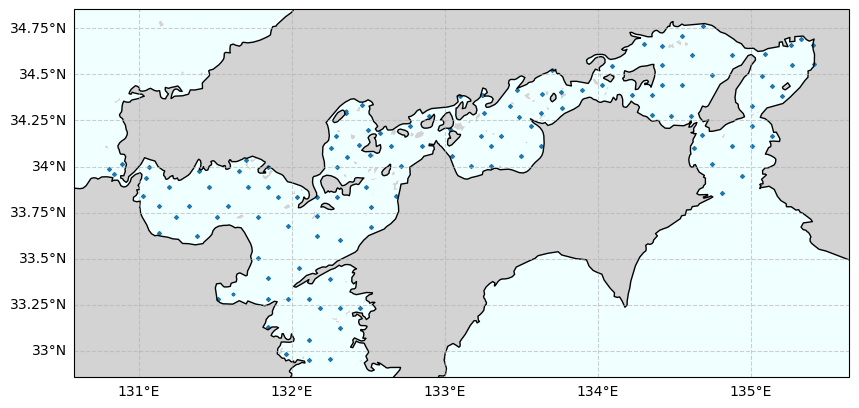

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# --- Quick Spatial Plot ---
if hasattr(df_to_inspect, 'geometry'):
    print("--- Spatial Distribution of Data Points ---")
    
    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})
    
    # Add background features
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN, facecolor='azure')
    ax.add_feature(cfeature.COASTLINE)
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.6)
    gl.top_labels = False
    gl.right_labels = False
    
    # Plot spatial data
    df_to_inspect.plot(ax=ax, markersize=2, alpha=0.5, transform=ccrs.PlateCarree())
    
    # Check Bounds
    bounds = df_to_inspect.total_bounds
    print(f"\nMap Bounds (MinX, MinY, MaxX, MaxY): {bounds}")
else:
    print("DataFrame does not have a geometry column.")

In [10]:
# === Find out the depth range of both 'saisuipoin' category ===

# Convert 'depth' column to numeric, forcing non-numeric values to NaN (since it is currently Object type)
merged_gdf['depth'] = pd.to_numeric(merged_gdf['depth'], errors='coerce')

# Group by 'saisuipoin' and calculate the minimum and maximum depth
depth_ranges = merged_gdf.groupby('saisuipoin')['depth'].agg(['min', 'max'])

# Display the results
print("Depth ranges for each 'saisuipoin' category:")
print(depth_ranges)

Depth ranges for each 'saisuipoin' category:
            min    max
saisuipoin            
1           0.5  179.0
2           1.1  179.0
